# 6. PCA + Classification

In [1]:
# Imports necessary libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import hashlib

# Generate seed based on my college ID.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed generated:", seed)
rng = np.random.default_rng(seed)

# Set plotting theme and helper functons.
sns.set_theme(context="paper", style="darkgrid",
              palette="rocket", font="Nimbus Roman")

def plotinfo(title, x, y, userid=username):
    plt.text(0.95, -0.1, userid, ha="right", va="top",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(x, fontsize=12)
    plt.ylabel(y, fontsize=12)
    plt.tight_layout()
    plt.show()

def coordplot(ax, title, x_label, y_label):
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

class PCA:
    """
    A custom implementation of Principal Component Analysis (PCA) from scratch.
    """
    def __init__(self, n_components):
        self.n_components = n_components
        self.components_ = None
        self.mean_ = None

    def fit(self, X):
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_
        cov_matrix = np.cov(X_centered, rowvar=False)
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
        sorted_indices = np.argsort(eigenvalues)[::-1]
        self.components_ = eigenvectors[:, sorted_indices][:, :self.n_components]
        
    def transform(self, X):
        if self.components_ is None:
            raise RuntimeError("PCA instance has not been fitted. Call fit() first.")
        X_centered = X - self.mean_
        return np.dot(X_centered, self.components_)

Seed generated: 1027714457


### 6.1 Data Loading and Preparation

### 6.2 Dimensionality Reduction with PCA

In [2]:
# Preprocessing: Split and scale the data.
digits = load_digits()
X, y = digits.data, digits.target
print(f"Dataset shape: {X.shape}") # 1797 samples, 64 features (8x8)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Dataset shape: (1797, 64)


### Classification with KNN

In [3]:
n_components_list = [2, 5, 10, 20, 30, 40, 50, 64]
k_values = [5, 25, 50, 100]

# Store results
results = []

print("\nRunning PCA and KNN classification.")
# Loop through each number of principal components
for n_comp in n_components_list:
    # Initialize and fit PCA on the training data
    pca = PCA(n_components=n_comp)
    pca.fit(X_train_scaled)
    
    # Transform both training and testing data
    X_train_pca = pca.transform(X_train_scaled)
    X_test_pca = pca.transform(X_test_scaled)
    
    # Loop through each k value for KNN
    for k in k_values:
        # Initialize and train the KNN classifier
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_train_pca, y_train)
        
        # Predict on the transformed test data
        y_pred = knn.predict(X_test_pca)
        
        # Calculate and store the accuracy
        accuracy = accuracy_score(y_test, y_pred)
        results.append({
            'n_components': n_comp,
            'k': k,
            'accuracy': accuracy
        })

# Convert results to a pandas DataFrame for easier plotting
results_df = pd.DataFrame(results)
print("Processing complete.")
print("\nFirst 5 results:")
print(results_df.head())


Running PCA and KNN classification.
Processing complete.

First 5 results:
   n_components    k  accuracy
0             2    5  0.522222
1             2   25  0.536111
2             2   50  0.519444
3             2  100  0.525000
4             5    5  0.830556


### Visualization and Analysis

1. **Effect of Principal Components on Accuracy**  
   - As the number of principal components increases, the classification accuracy of the KNN classifier improves significantly at first.  
   - The most dramatic improvement occurs between **2 and 10 principal components**, where accuracy jumps sharply across all values of *k*.  
   - After around **30 components**, the accuracy plateaus, suggesting that most of the important variance in the data has already been captured.

2. **Influence of k (Number of Neighbors)**  
   - Lower values of *k* (e.g., **k = 5**) consistently achieve higher accuracy compared to larger values of *k*.  
   - Larger *k* values (e.g., **k = 50 or 100**) result in smoother but slightly lower accuracy curves, indicating that they may underfit the data.  
   - Intermediate values (e.g., **k = 25**) strike a balance, performing reasonably well while being less sensitive to noise than very small *k*.

3. **Point of Diminishing Returns**  
   - Beyond about **30–40 principal components**, adding more components does not yield substantial gains in accuracy for any value of *k*.  
   - This indicates a **point of diminishing returns**, where increasing dimensionality only adds computational cost without improving performance.  

Hence, the optimal setup is achieved with a relatively small number of principal components (≈ 30) and a small *k* (around 5), which provides the best classification accuracy while avoiding unnecessary complexity.


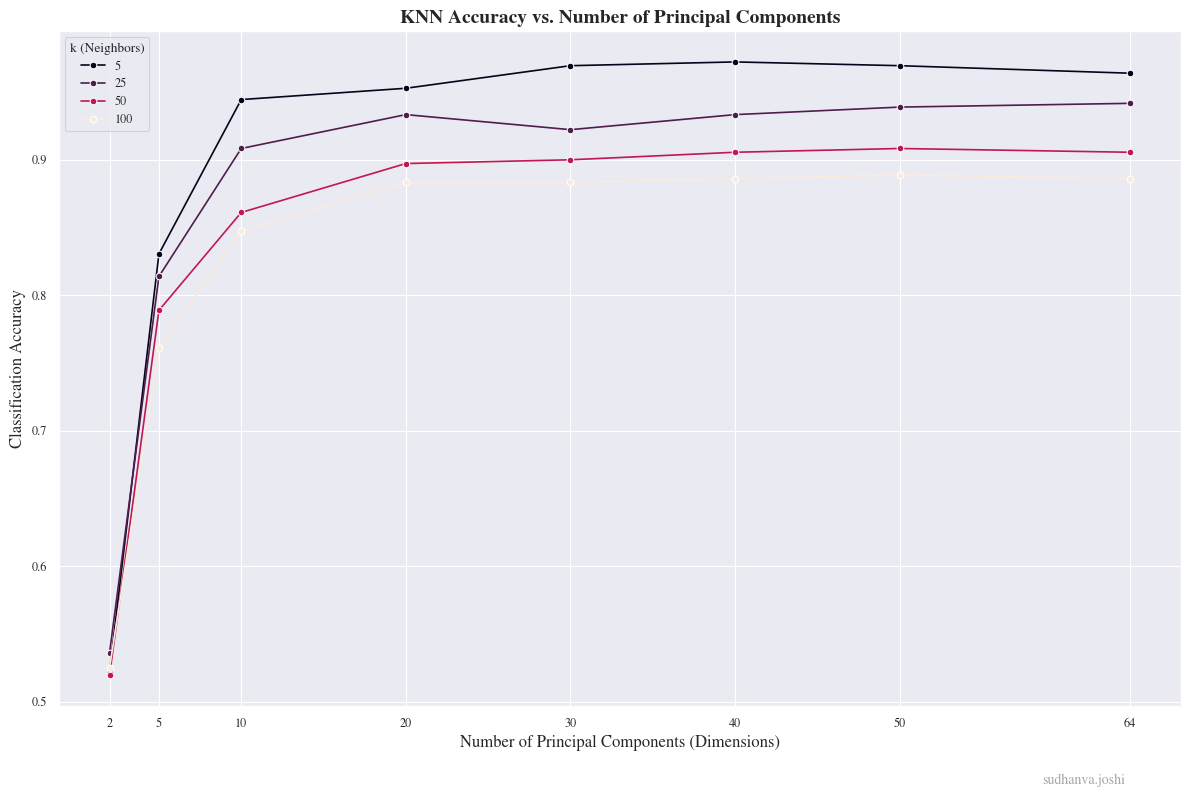

In [4]:
# Create the plot
plt.figure(figsize=(12, 8))

sns.lineplot(data=results_df, x='n_components', y='accuracy',
    hue='k', palette='rocket', marker='o', legend='full')
plt.xticks(n_components_list)
plt.legend(title='k (Neighbors)')
plotinfo('KNN Accuracy vs. Number of Principal Components',
         'Number of Principal Components (Dimensions)',
         'Classification Accuracy')
plt.show()